# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión A

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:** Ariadna Georgina Gómez Robledo  
**Grupo:** 512 **Fecha:** 26/10/2026

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la distancia recorrida y la duración del viaje?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`trip_distance`** y **`trip_duration`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_A_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_A/
└── notebooks/
    └── Examen_A_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
# 1. Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)

# 2. Carga del CSV (ruta relativa a la carpeta notebooks/)
# La primera columna del archivo es el índice que se guardó al exportarlo, por eso uso index_col=0
ruta = "../data/raw/nyc_taxi_examen.csv"
df = pd.read_csv(ruta, index_col=0)

# 3. Primeras filas, dimensiones, columnas y tipos
print("Primeras cinco filas:")
display(df.head())

print("Dimensiones (filas, columnas):", df.shape)

print("\nNombres de las columnas:")
print(df.columns.tolist())

print("\nTipos de datos:")
print(df.dtypes)


Primeras cinco filas:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


Dimensiones (filas, columnas): (2427612, 20)

Nombres de las columnas:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']

Tipos de datos:
VendorID                   int64
tpep_pickup_datetime      object
tpep_dropoff_datetime     object
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type              object
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport

In [2]:
# 4. Resumen estadístico de las columnas numéricas
display(df.describe().T.round(2))


,count,mean,std,min,25%,50%,75%,max
VendorID,2427612.0,1.89,0.81,1.00,2.00,2.00,2.00,7.00
passenger_count,2415489.0,1.30,1.88,-5.00,1.00,1.00,1.00,100.00
trip_distance,2415470.0,3.30,5.17,-99.99,0.99,1.70,3.36,1686.49
RatecodeID,2415474.0,4.23,17.20,1.00,1.00,1.00,1.00,99.00
PULocationID,2415487.0,164.14,62.85,1.00,132.00,161.00,232.00,265.00
DOLocationID,2415475.0,163.22,69.26,1.00,113.00,162.00,234.00,265.00
fare_amount,2415488.0,38.53,542.38,-1849.60,9.30,13.50,21.90,19995.59
extra,2415487.0,1.57,1.91,-7.50,0.00,1.00,2.50,23.25
mta_tax,2415462.0,0.48,0.10,-0.50,0.50,0.50,0.50,11.50
tip_amount,2415459.0,3.67,4.23,-90.00,1.00,2.95,4.56,444.44


In [3]:
# 5. Valores que existen en payment_type
print(df["payment_type"].value_counts(dropna=False))


payment_type
Credit card    2051983
Cash            329533
Dispute          23558
NaN              12125
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [4]:
# 1. Copia de los datos originales
df_limpio = df.copy()
print("Dimensiones antes de limpiar:", df_limpio.shape)

# 2. Nulos por columna y duplicados antes de limpiar
print("\nValores nulos por columna:")
print(df_limpio.isnull().sum())

print("\nRegistros duplicados:", df_limpio.duplicated().sum())

# 3. Eliminar duplicados y filas con nulos
df_limpio = df_limpio.drop_duplicates()
print("\nDespués de quitar duplicados:", df_limpio.shape)

df_limpio = df_limpio.dropna()
print("Después de quitar nulos:", df_limpio.shape)

# 4. Conservar solo los registros que cumplen todas las condiciones
condiciones = (
    (df_limpio["trip_distance"] > 0)
    & (df_limpio["passenger_count"] > 0) & (df_limpio["passenger_count"] < 100)
    & (df_limpio["fare_amount"] > 0) & (df_limpio["fare_amount"] < 10000)
    & (df_limpio["trip_duration"] > 0)
)
df_limpio = df_limpio[condiciones].copy()

# 5. Registros que quedan
print("\nDimensiones después de limpiar:", df_limpio.shape)
print("Registros eliminados en total:", len(df) - len(df_limpio))


Dimensiones antes de limpiar: (2427612, 20)

Valores nulos por columna:
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Registros duplicados: 11961

Después de quitar duplicados: (2415651, 20)
Después de quitar nulos: (2196158, 20)

Dimensiones después de limpiar: (2096600, 20)
Registros eliminados en total: 331012


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`trip_distance`** y **`trip_duration`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [6]:
# 1. Cash
df_cash = df_limpio[df_limpio["payment_type"] == "Cash"].copy()

# 2. Agrupamiento
X = df_cash[["trip_distance", "trip_duration"]]

# 3. Cantidad de viajes y estadísticas descriptivas
print("Viajes pagados en efectivo:", len(df_cash))
display(X.describe().round(2))


Viajes pagados en efectivo: 282085


,trip_distance,trip_duration
count,282085.00,282085.00
mean,3.84,17.51
std,6.21,40.68
min,0.01,0.03
25%,0.92,7.40
50%,1.70,12.42
75%,4.37,20.88
max,1686.49,8373.67


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [7]:
# 1. Transformación logarítmica
X_log = np.log1p(X)

# 2 y 3. Estandarización
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X_log)

# Guardar los datos estandarizados
X_escalado = pd.DataFrame(X_escalado, columns=X.columns, index=X.index)

# 4. Comprobación: media cercana a 0 y desviación estándar cercana a 1
print("Variables después de log1p:")
display(X_log.describe().round(2))

print("Variables después de log1p + StandardScaler:")
display(X_escalado.describe().round(2))


Variables después de log1p:


,trip_distance,trip_duration
count,282085.00,282085.00
mean,1.23,2.61
std,0.76,0.74
min,0.01,0.03
25%,0.65,2.13
50%,0.99,2.60
75%,1.68,3.09
max,7.43,9.03


Variables después de log1p + StandardScaler:


,trip_distance,trip_duration
count,282085.00,282085.00
mean,-0.00,-0.00
std,1.00,1.00
min,-1.59,-3.46
25%,-0.75,-0.64
50%,-0.30,-0.01
75%,0.60,0.64
max,8.13,8.63


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [8]:
# 1 a 4. Evaluar k = 2 a 6
resultados = []

for k in range(2, 7):
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas_k = modelo.fit_predict(X_escalado)

    silueta = silhouette_score(X_escalado, etiquetas_k, sample_size=5000, random_state=42)

    resultados.append({"k": k, "Inercia": modelo.inertia_, "Silueta": silueta})

# 5. Tabla comparativa
tabla_k = pd.DataFrame(resultados)
display(tabla_k.round(3))


,k,Inercia,Silueta
0,2,227681.229,0.532
1,3,137511.959,0.448
2,4,100620.195,0.419
3,5,79205.372,0.389
4,6,66980.310,0.374


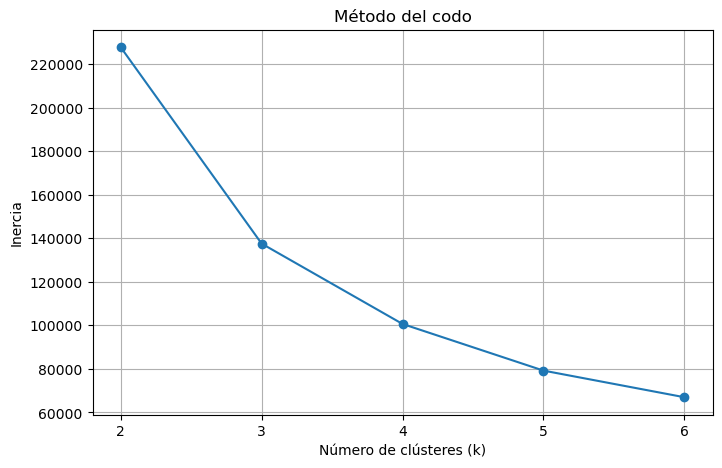

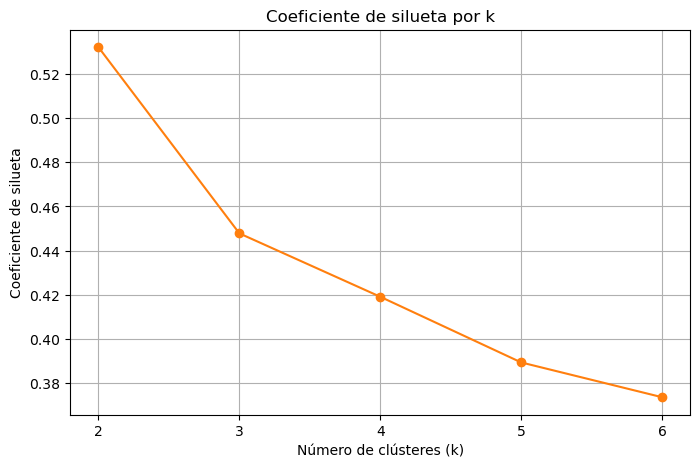

In [9]:
# 6. Gráfica del método del codo
plt.figure(figsize=(8, 5))
plt.plot(tabla_k["k"], tabla_k["Inercia"], marker="o")
plt.title("Método del codo")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Inercia")
plt.xticks(tabla_k["k"])
plt.grid(True)
plt.show()

# Gráfica del coeficiente de silueta
plt.figure(figsize=(8, 5))
plt.plot(tabla_k["k"], tabla_k["Silueta"], marker="o", color="tab:orange")
plt.title("Coeficiente de silueta por k")
plt.xlabel("Número de clústeres (k)")
plt.ylabel("Coeficiente de silueta")
plt.xticks(tabla_k["k"])
plt.grid(True)
plt.show()


## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`trip_distance`**, eje Y = **`trip_duration`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

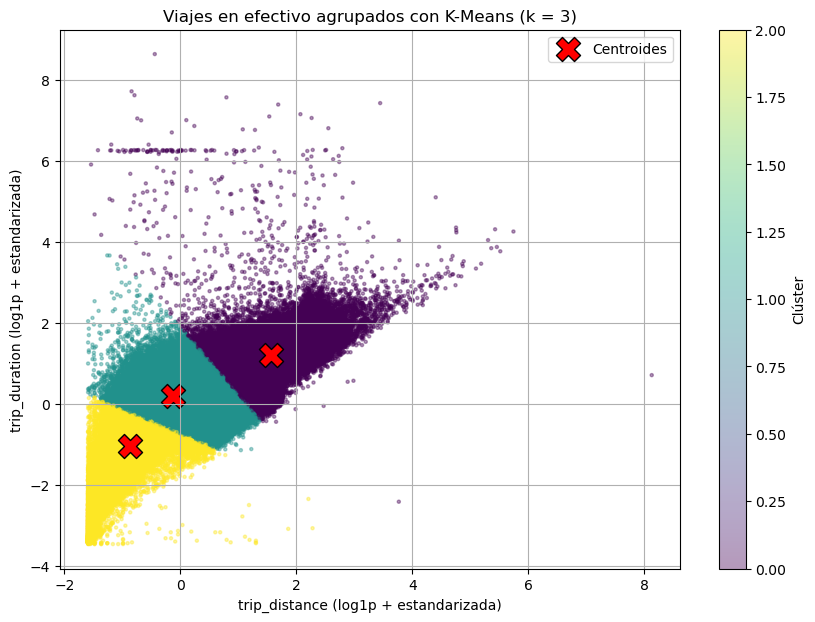

In [10]:
# 1. Valor de k elegido 
k_elegido = 3

# 2 y 3. Modelo final y etiquetas
modelo_final = KMeans(n_clusters=k_elegido, random_state=42, n_init=10)
etiquetas = modelo_final.fit_predict(X_escalado)
centroides = modelo_final.cluster_centers_

# 4 a 7. Gráfica de dispersión con clústeres y centroides
plt.figure(figsize=(10, 7))
puntos = plt.scatter(
    X_escalado["trip_distance"],
    X_escalado["trip_duration"],
    c=etiquetas,
    cmap="viridis",
    s=5,
    alpha=0.4
)
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=300,
    c="red",
    edgecolors="black",
    label="Centroides"
)
plt.colorbar(puntos, label="Clúster")
plt.title(f"Viajes en efectivo agrupados con K-Means (k = {k_elegido})")
plt.xlabel("trip_distance (log1p + estandarizada)")
plt.ylabel("trip_duration (log1p + estandarizada)")
plt.legend()
plt.grid(True)
plt.show()


## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `trip_distance`.
   - **Media y mediana** de `trip_duration`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: millas para la distancia y minutos para la duración.

**Evidencia:** tabla de estadísticos por clúster.

In [11]:
# 1 y 2. Datos originales con la etiqueta de clúster
df_resultado = df_cash.copy()
df_resultado["cluster"] = etiquetas

# 3. Estadísticos por clúster en unidades originales (millas y minutos)
estadisticos = df_resultado.groupby("cluster").agg(
    cantidad_viajes=("trip_distance", "count"),
    distancia_media_millas=("trip_distance", "mean"),
    distancia_mediana_millas=("trip_distance", "median"),
    duracion_media_min=("trip_duration", "mean"),
    duracion_mediana_min=("trip_duration", "median"),
)

# 4. Tabla redondeada a dos decimales
display(estadisticos.round(2))


,cantidad_viajes,distancia_media_millas,distancia_mediana_millas,duracion_media_min,duracion_mediana_min
cluster,,,,,
0,62395,11.55,9.81,39.48,31.40
1,125521,2.30,1.94,15.43,14.00
2,94169,0.80,0.76,5.72,5.82


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:** Elegí **k = 3**.

- **Inercia (codo):** al pasar de k=2 a k=3 la inercia baja de 227,681 a 137,512. De 3 a 4 solo baja 36,892 y de ahí en adelante cada grupo extra reduce cada vez menos (21,415 y 12,225). El codo se ve en k=3.
- **Silueta:** la silueta más alta es la de k=2 (0.532), pero k=3 sigue teniendo un valor bueno (0.448) y es mayor que el de k=4, 5 y 6. Eso indica que con 3 grupos los viajes siguen bien separados.
- **Claridad de los grupos:** con k=2 solo separaríamos viajes "cortos" y "largos". Con k=3 aparecen tres tipos fáciles de explicar (muy cortos, medianos y largos), y en la gráfica los tres grupos se ven separados con sus centroides en zonas distintas. Por eso preferí k=3 aunque su silueta sea un poco menor que la de k=2.

**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**

- **Clúster 2 — "Viajes muy cortos":** 94,169 viajes (33.4%). La distancia media es de 0.80 millas (mediana 0.76) y la duración media de 5.72 minutos (mediana 5.82). Son trayectos de unas cuantas cuadras.
- **Clúster 1 — "Viajes medianos urbanos":** 125,521 viajes (44.5%). La distancia media es de 2.30 millas (mediana 1.94) y la duración media de 15.43 minutos (mediana 14.00). Son los viajes típicos dentro de la ciudad.
- **Clúster 0 — "Viajes largos":** 62,395 viajes (22.1%). La distancia media es de 11.55 millas (mediana 9.81) y la duración media de 39.48 minutos (mediana 31.40). Probablemente incluyen viajes al aeropuerto o entre distritos.

En el clúster 0 la media es más alta que la mediana, sobre todo en la duración (39.48 contra 31.40). Esto quiere decir que hay algunos viajes extremos muy largos que suben el promedio. Por eso la mediana describe mejor al viaje típico de ese grupo.

**Pregunta 3 — Análisis sencillo.** ¿Qué clúster presenta la mayor duración promedio? ¿También tiene la mayor distancia promedio? Explica usando la tabla.

**Respuesta:** El **clúster 0** tiene la mayor duración promedio, con 39.48 minutos. **Sí**, también tiene la mayor distancia promedio, con 11.55 millas. Eso tiene sentido, porque los viajes más largos en distancia tardan más. La relación se mantiene en los tres grupos: a mayor distancia promedio (0.80 -> 2.30 -> 11.55 millas), mayor duración promedio (5.72 → 15.43 → 39.48 minutos).

**Pregunta 4 — Análisis sencillo.** ¿Cuál es el grupo más numeroso? ¿Qué características de distancia y duración predominan en ese grupo?

**Respuesta:** El grupo más numeroso es el **clúster 1, "Viajes medianos urbanos"**, con 125,521 viajes, casi la mitad (44.5%) de los viajes pagados en efectivo. En ese grupo predominan distancias cortas a medianas, de alrededor de 2 millas (media 2.30, mediana 1.94), y duraciones de unos 15 minutos (media 15.43, mediana 14.00). Como la media y la mediana son parecidas, el grupo es bastante homogéneo: la mayoría de las personas que pagan en efectivo hacen trayectos cortos dentro de la ciudad.


---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**